# 04 · Evaluación e interpretación

**Fase CRISP-DM:** 5 – Evaluación

Se analizan las predicciones *out-of-fold* (5 folds por paciente) del modelo final: el ensamble 50/50
de las dos mejores CNNs (si existe) o, en su defecto, la mejor CNN en validación cruzada.

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath("../.."))  # raíz del repo (notebooks/iteracion_2/ -> ../..)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, roc_curve, roc_auc_score
from src.config import RESULTS_DIR, FIGURES_DIR, OOF_DIR, CACHE_DIR, TARGETS, CLASSES
from src.evaluate import all_metrics, per_class_report, kl_divergence
from src.viz import set_style, CLASS_COLORS, SEQ_CMAP, PALETTE
set_style()
FIG = FIGURES_DIR / "evaluacion"; FIG.mkdir(exist_ok=True, parents=True)

metrics = pd.read_csv(RESULTS_DIR / "metrics.csv")
if (OOF_DIR / "ensemble.csv").exists():
    NAME = "ensemble"
else:
    cv = metrics[(metrics.folds.astype(str) == "all") & (metrics.stage == 2)].sort_values("kl")
    NAME = cv.experiment.iloc[0]
oof = pd.read_csv(OOF_DIR / f"{NAME}.csv")
Y = oof[TARGETS].to_numpy(); P = oof[[f"pred_{t}" for t in TARGETS]].to_numpy()
votes = oof.total_votes.to_numpy(); hq = votes >= 10
yt, yp = Y.argmax(1), P.argmax(1)
print("Modelo evaluado:", NAME, "| muestras OOF:", len(oof))
pd.DataFrame({"todas": all_metrics(Y, P), ">=10 votos": all_metrics(Y[hq], P[hq]),
              "<10 votos": all_metrics(Y[~hq], P[~hq])}).round(4)

Modelo evaluado: ensemble | muestras OOF: 17089


,todas,>=10 votos,<10 votos
kl,0.5757,0.3474,0.6811
accuracy,0.7173,0.7376,0.7079
macro_f1,0.6331,0.5857,0.6387
macro_auc,0.9235,0.9284,0.9248


## 1. Matriz de confusión (clase mayoritaria)

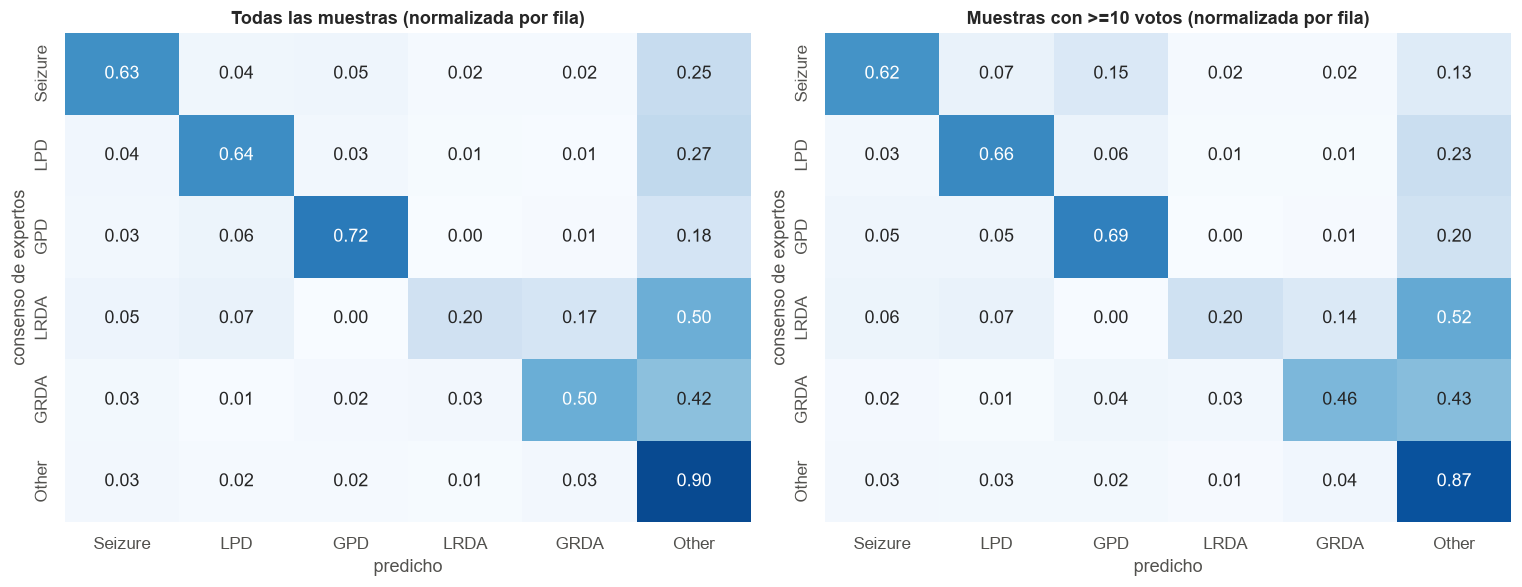

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
for ax, mask, title in [(axes[0], np.ones_like(hq), "Todas las muestras"), (axes[1], hq, "Muestras con >=10 votos")]:
    cm = confusion_matrix(yt[mask], yp[mask], labels=range(6), normalize="true")
    sns.heatmap(pd.DataFrame(cm, CLASSES, CLASSES), annot=True, fmt=".2f", cmap=SEQ_CMAP, vmin=0, vmax=1, ax=ax, cbar=False)
    ax.set_xlabel("predicho"); ax.set_ylabel("consenso de expertos"); ax.set_title(f"{title} (normalizada por fila)")
fig.tight_layout(); fig.savefig(FIG / "matriz_confusion.png"); plt.show()

## 2. Métricas clínicas por clase
Sensibilidad (recall), especificidad, precisión, F1 y AUC uno-contra-resto.

In [3]:
rep_all = per_class_report(Y, P).set_index("clase")
rep_hq = per_class_report(Y[hq], P[hq]).set_index("clase")
display(rep_all.round(3))
display(rep_hq.round(3).add_suffix("_hq"))

,soporte,sensibilidad,especificidad,precision,f1,auc
clase,,,,,,
Seizure,2800,0.631,0.969,0.798,0.705,0.936
LPD,2573,0.644,0.971,0.800,0.714,0.947
GPD,1799,0.719,0.975,0.774,0.745,0.959
LRDA,934,0.201,0.988,0.485,0.284,0.879
GRDA,1828,0.501,0.969,0.663,0.571,0.917
Other,7155,0.900,0.706,0.688,0.779,0.902


,soporte_hq,sensibilidad_hq,especificidad_hq,precision_hq,f1_hq,auc_hq
clase,,,,,,
Seizure,182,0.621,0.967,0.396,0.484,0.957
LPD,1031,0.660,0.967,0.824,0.733,0.945
GPD,692,0.692,0.963,0.732,0.712,0.961
LRDA,250,0.204,0.987,0.436,0.278,0.885
GRDA,386,0.459,0.967,0.515,0.485,0.922
Other,2855,0.869,0.728,0.782,0.823,0.900


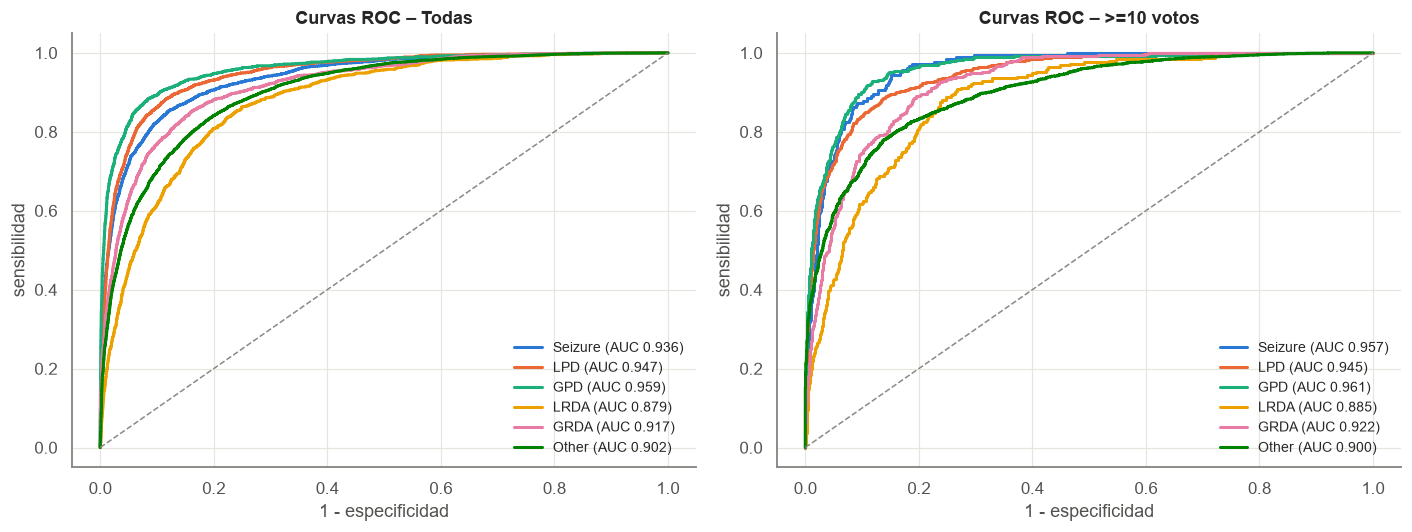

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, mask, title in [(axes[0], np.ones_like(hq), "Todas"), (axes[1], hq, ">=10 votos")]:
    for k, c in enumerate(CLASSES):
        fpr, tpr, _ = roc_curve(yt[mask] == k, P[mask, k])
        ax.plot(fpr, tpr, lw=2, color=CLASS_COLORS[c], label=f"{c} (AUC {roc_auc_score(yt[mask] == k, P[mask, k]):.3f})")
    ax.plot([0, 1], [0, 1], color="#8a8984", ls="--", lw=1)
    ax.set_xlabel("1 - especificidad"); ax.set_ylabel("sensibilidad"); ax.set_title(f"Curvas ROC – {title}")
    ax.legend(loc="lower right", fontsize=9)
fig.tight_layout(); fig.savefig(FIG / "roc.png"); plt.show()

## 3. Calibración
Como el objetivo es una distribución, se compara la probabilidad predicha con la fracción real de
votos de esa clase (por deciles de probabilidad predicha).

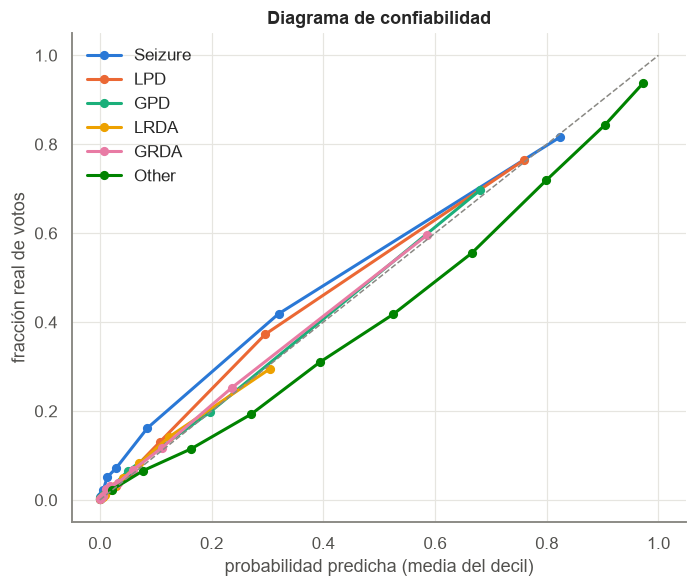

In [5]:
fig, ax = plt.subplots(figsize=(6.5, 5.5))
for k, c in enumerate(CLASSES):
    df = pd.DataFrame({"p": P[:, k], "y": Y[:, k]})
    df["bin"] = pd.qcut(df.p, 10, duplicates="drop")
    g = df.groupby("bin", observed=True).mean()
    ax.plot(g.p, g.y, marker="o", ms=5, lw=2, color=CLASS_COLORS[c], label=c)
ax.plot([0, 1], [0, 1], color="#8a8984", ls="--", lw=1)
ax.set_xlabel("probabilidad predicha (media del decil)"); ax.set_ylabel("fracción real de votos")
ax.set_title("Diagrama de confiabilidad"); ax.legend()
fig.tight_layout(); fig.savefig(FIG / "calibracion.png"); plt.show()

## 4. Error según cantidad de votos y acuerdo entre expertos

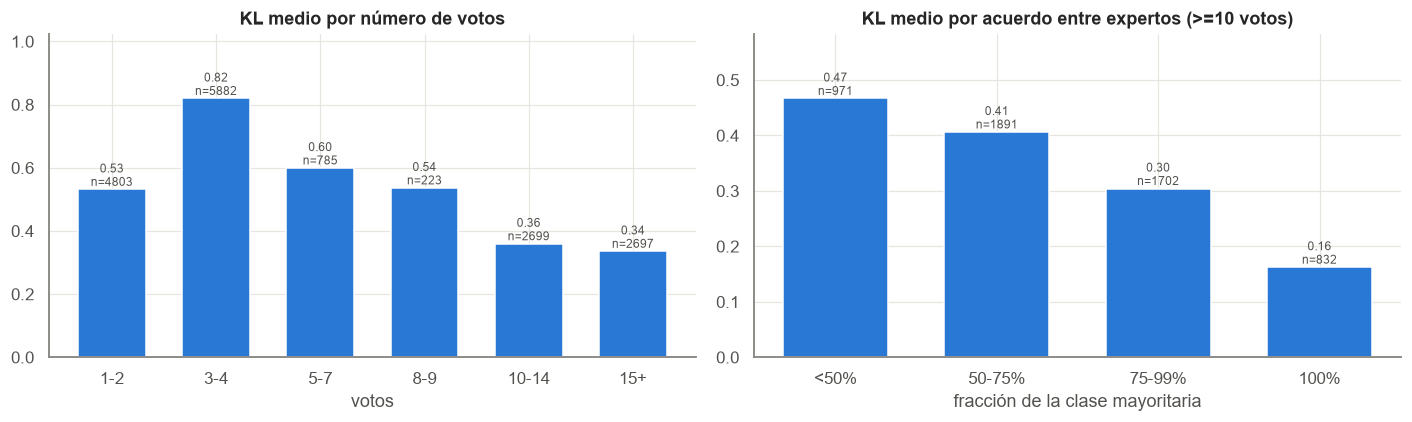

In [6]:
with np.errstate(divide="ignore", invalid="ignore"):
    kl_row = np.where(Y > 0, Y * np.log(Y / np.clip(P, 1e-15, 1)), 0).sum(axis=1)
oof["kl_row"] = kl_row
oof["acuerdo"] = Y.max(axis=1)
oof["votos_bin"] = pd.cut(oof.total_votes, [0, 2, 4, 7, 9.99, 14, 30], labels=["1-2", "3-4", "5-7", "8-9", "10-14", "15+"])
oof["acuerdo_bin"] = pd.cut(oof.acuerdo, [0, .5, .75, .99, 1], labels=["<50%", "50-75%", "75-99%", "100%"])
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
g = oof.groupby("votos_bin", observed=True).kl_row.agg(["mean", "size"])
axes[0].bar(g.index.astype(str), g["mean"], color=PALETTE[0], width=0.65)
for i, (m, n) in enumerate(zip(g["mean"], g["size"])): axes[0].text(i, m, f"{m:.2f}\nn={n}", ha="center", va="bottom", fontsize=8, color="#52514e")
axes[0].set_title("KL medio por número de votos"); axes[0].set_xlabel("votos"); axes[0].margins(y=0.25)
g = oof[hq].groupby("acuerdo_bin", observed=True).kl_row.agg(["mean", "size"])
axes[1].bar(g.index.astype(str), g["mean"], color=PALETTE[0], width=0.65)
for i, (m, n) in enumerate(zip(g["mean"], g["size"])): axes[1].text(i, m, f"{m:.2f}\nn={n}", ha="center", va="bottom", fontsize=8, color="#52514e")
axes[1].set_title("KL medio por acuerdo entre expertos (>=10 votos)"); axes[1].set_xlabel("fracción de la clase mayoritaria"); axes[1].margins(y=0.25)
fig.tight_layout(); fig.savefig(FIG / "kl_por_votos.png"); plt.show()

## 5. Variabilidad entre folds (pacientes distintos)

In [7]:
fold_rows = []
for f, d in oof.groupby("fold"):
    m = all_metrics(d[TARGETS].to_numpy(), d[[f"pred_{t}" for t in TARGETS]].to_numpy(), d.total_votes)
    fold_rows.append({"fold": f, "n": len(d), **m})
ft = pd.DataFrame(fold_rows).set_index("fold")
display(ft.round(4))
print("media ± desv:", {k: f"{ft[k].mean():.4f} ± {ft[k].std():.4f}" for k in ["kl", "kl_hq", "accuracy", "macro_auc"]})

,n,kl,accuracy,macro_f1,macro_auc,kl_hq,accuracy_hq
fold,,,,,,,
0,3418,0.6075,0.7147,0.6265,0.9160,0.3263,0.7585
1,3418,0.5741,0.7136,0.6397,0.9346,0.3182,0.7640
2,3418,0.5529,0.7364,0.6533,0.9194,0.3554,0.7258
3,3418,0.5973,0.7142,0.6214,0.9203,0.3947,0.7195
4,3417,0.5467,0.7076,0.6215,0.9260,0.3404,0.7211


media ± desv: {'kl': '0.5757 ± 0.0266', 'kl_hq': '0.3470 ± 0.0302', 'accuracy': '0.7173 ± 0.0110', 'macro_auc': '0.9233 ± 0.0073'}


## 6. Peores casos
Muestras de alto acuerdo (≥10 votos, ≥75 % de acuerdo) donde el modelo más se equivoca.

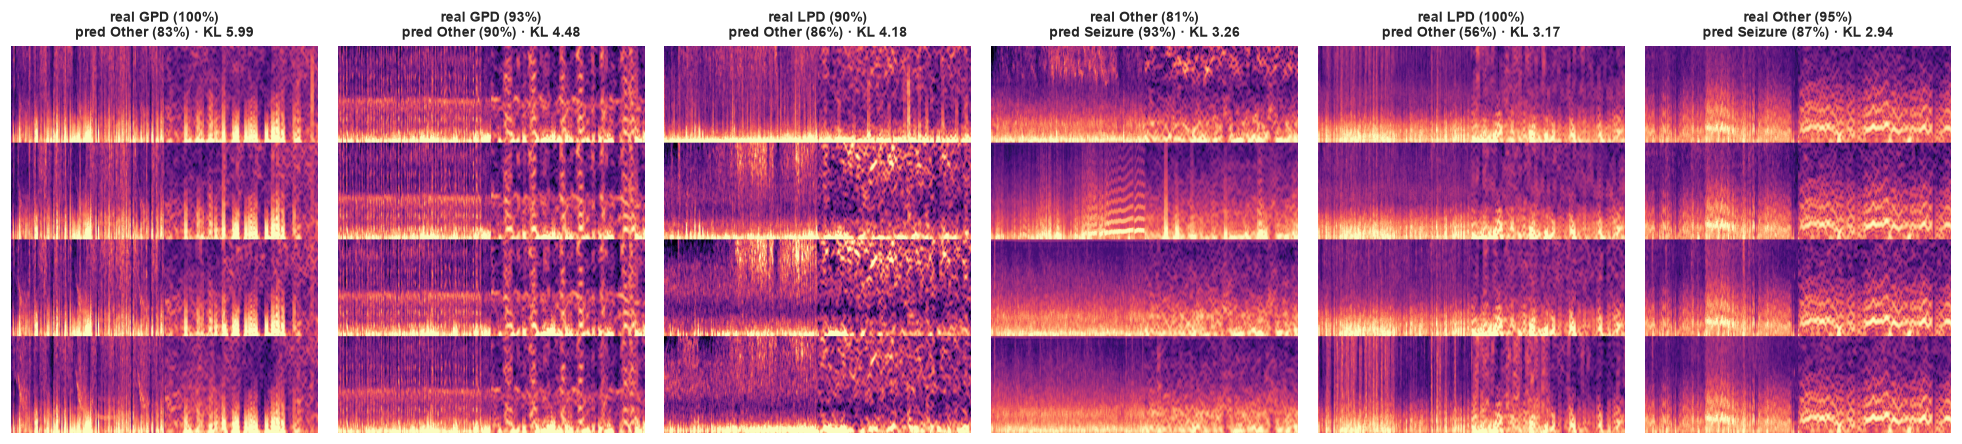

In [8]:
meta = pd.read_csv(CACHE_DIR / "meta.csv")
X = np.load(CACHE_DIR / "images.npy", mmap_mode="r")
pos = pd.Series(meta.index, index=meta.eeg_id)
worst = oof[hq & (oof.acuerdo >= .75)].sort_values("kl_row", ascending=False).head(6)
fig, axes = plt.subplots(1, 6, figsize=(18, 4.2))
for ax, (_, r) in zip(axes, worst.iterrows()):
    x = np.asarray(X[pos[r.eeg_id]], dtype=np.float32)
    img = np.concatenate([np.concatenate(x[:4], 0), np.concatenate(x[4:], 0)], 1)
    ax.imshow(img, cmap="magma", vmin=-2.5, vmax=2.5, aspect="auto"); ax.axis("off")
    pr = r[[f"pred_{t}" for t in TARGETS]].to_numpy(float)
    ax.set_title(f"real {CLASSES[int(np.argmax(r[TARGETS].to_numpy(float)))]} ({r.acuerdo:.0%})\n"
                 f"pred {CLASSES[pr.argmax()]} ({pr.max():.0%}) · KL {r.kl_row:.2f}", fontsize=9)
fig.tight_layout(); fig.savefig(FIG / "peores_casos.png"); plt.show()

In [9]:
err = oof[hq & (yt != yp)]
pairs = pd.Series([f"{CLASSES[a]} → {CLASSES[b]}" for a, b in zip(yt[hq & (yt != yp)], yp[hq & (yt != yp)])]).value_counts()
pairs.head(10).to_frame("errores (>=10 votos)")

,errores (>=10 votos)
LPD → Other,235
GRDA → Other,167
GPD → Other,136
LRDA → Other,130
Other → GRDA,110
Other → Seizure,80
Other → LPD,76
Other → GPD,69
LPD → GPD,62
Other → LRDA,40


## 7. Comparación del modelo con la "confusión humana"
Para cada clase de consenso (≥10 votos) se compara la distribución media de votos de los expertos
con la distribución media predicha. Si se parecen, el modelo reproduce el desacuerdo humano en
lugar de sobre-confiarse.

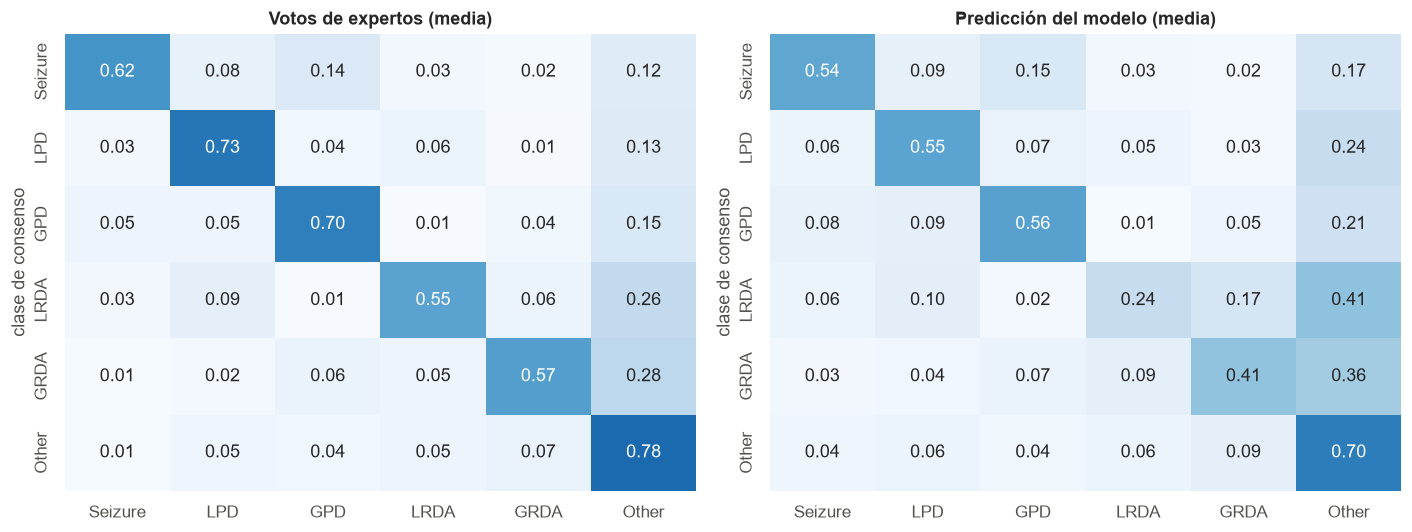

In [10]:
hum = pd.DataFrame(Y[hq], columns=CLASSES).groupby(np.array(CLASSES)[yt[hq]]).mean().reindex(CLASSES)
mod = pd.DataFrame(P[hq], columns=CLASSES).groupby(np.array(CLASSES)[yt[hq]]).mean().reindex(CLASSES)
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, d, t in [(axes[0], hum, "Votos de expertos (media)"), (axes[1], mod, "Predicción del modelo (media)")]:
    sns.heatmap(d, annot=True, fmt=".2f", cmap=SEQ_CMAP, vmin=0, vmax=1, ax=ax, cbar=False)
    ax.set_title(t); ax.set_ylabel("clase de consenso"); ax.set_xlabel("")
fig.tight_layout(); fig.savefig(FIG / "humano_vs_modelo.png"); plt.show()

## 8. Conclusiones de la evaluación (ensamble EfficientNet-B0 + ConvNeXt-T, 5 folds)

**Desempeño global.** KL = **0.576** en todas las muestras y **0.347** en las de ≥10 votos; accuracy
71.7 %, AUC macro **0.924**. La variación entre folds (pacientes distintos) es baja: KL 0.576 ± 0.027,
AUC 0.923 ± 0.007. Frente al mejor baseline clásico (HGB, KL 0.882 / 0.656) la mejora es de ~35 % / ~47 %.

**Por clase.** Las descargas periódicas son las mejor reconocidas (GPD: sensibilidad 0.72, AUC 0.96;
LPD: 0.64, AUC 0.95). *Seizure* tiene AUC alta (0.94–0.96) pero, en el subconjunto de alta calidad, una
precisión de solo 0.40 porque allí hay apenas 182 crisis. **LRDA es el punto débil** (sensibilidad 0.20):
es la clase más rara (5.5 %) y la que los propios expertos más confunden con *Other* y GRDA.

**Sesgo hacia *Other*.** Casi todos los errores frecuentes son "patrón → Other" (LPD→Other, GRDA→Other,
GPD→Other, LRDA→Other). Comparando con la confusión humana (≥10 votos): los expertos asignan en promedio
0.26 de sus votos a *Other* en casos LRDA y el modelo 0.41; en GRDA 0.28 vs. 0.36. El diagrama de
confiabilidad lo confirma (*Other* sobre-predicho en todo el rango). Es un comportamiento "prudente"
aprendido de la clase mayoritaria (42 % de los EEG) y de las muestras con pocos votos.

**El error sigue al desacuerdo humano.** En alta calidad, la KL media es 0.16 cuando los expertos son
unánimes y 0.48 cuando la clase mayoritaria tiene <50 % de los votos. Las muestras con 3–4 votos son
las peores: suelen ser etiquetas casi *one-hot* de pocos anotadores, que la KL castiga cuando el modelo
reparte probabilidad.

**Peores casos.** Varios errores graves son GPD/LPD con descargas periódicas claramente visibles
(franjas verticales regulares) clasificadas como *Other* con >80 % de confianza: son fallos reales del
modelo, no ruido de etiqueta, y apuntan a usar más resolución temporal o contexto del EEG.

**Implicaciones clínicas.** Con especificidades de 0.96–0.99 para las clases patológicas, el modelo es
útil como herramienta de **priorización** (ordenar registros por probabilidad de patrón dañino), no como
diagnóstico autónomo: la sensibilidad para LRDA/GRDA y para crisis en casos difíciles aún es insuficiente.